In [45]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [46]:
%cd /content/drive/MyDrive/ColabNotebooks/ICT110_AppDev_Hallador/ColabNotes

/content/drive/MyDrive/ColabNotebooks/ICT110_AppDev_Hallador/ColabNotes


In [47]:
!pwd

/content/drive/MyDrive/ColabNotebooks/ICT110_AppDev_Hallador/ColabNotes


In [48]:
ls

'Copy of ML_Workbook_Wisconsin_Diagnostic.ipynb'   Datasets/   Exercises.ipynb


# Workbook Exercise: Breast Cancer Diagnosis — An End-to-End Classification Project

**Course:** Machine Learning / Applied AI  **Level:** Intermediate  **Estimated time:** 2 hours

**Learning objectives.** By the end of this workbook you will be able to:
1. Frame a real-world problem as a supervised learning task.
2. Summarize and visualize a dataset to understand its structure before modeling.
3. Clean data, select informative features and apply appropriate transforms.
4. Build a leak-free test harness and spot-check several algorithms.
5. Improve accuracy through tuning and ensembles, then report honest test results.

**How to use this workbook.** Run the cells in order. Wherever you see `# TODO`, replace the `...` with your own code (hints are given). Cells marked ✏️ ask for a written answer: double-click to edit. Do not look at the answer key until you have tried each exercise.

**Outline**
- A. Problem Definition
- B. Summarize and Analyze Data
- C. Prepare Data
- D. Evaluate Algorithm
- E. Improve Accuracy



## Before you begin

> First, make a copy of this notebook so that you can make changes as you please.
> Run and edit the copy instead of this original notebook.

> To copy this notebook, go to `File|Save a Copy to Drive`.

**Gentle Reminder**
> Once finish, Kindly `push` this notebook to your GitHub repo.**

---
## A. Problem Definition

### A.1 Brief Description
The **Breast Cancer Wisconsin (Diagnostic)** dataset contains measurements computed from digitized images of fine-needle aspirates (FNA) of breast masses. Each row describes the characteristics of the cell nuclei present in one image.

- **569 instances**, **30 numeric features**, **1 binary target**
- Features are 10 nucleus measurements (radius, texture, perimeter, area, smoothness, compactness, concavity, concave points, symmetry, fractal dimension), each reported as the **mean**, the **standard error** and the **worst** (largest) value.
- Target: `0` = malignant, `1` = benign.

### A.2 Problem Statement
✏️ **Exercise A.1.** In 3–4 sentences, write a problem statement in your own words. Include: (a) the prediction task, (b) the input data, (c) the type of learning problem, (d) which kind of error is more costly and why, and (e) how you will judge success.

> **Your answer:** This project builds a supervised binary classification model to predict whether a breast tumor is malignant or benign. The model uses 30 continuous features extracted from fine-needle aspirate cell images as input data. A false negative error is far more costly than a false positive because missing a cancer diagnosis delays critical medical treatment, so success is judged by maximizing recall for malignant cases alongside high overall accuracy.

### A.3 Load Packages
**Exercise A.2.** The imports below are mostly done. Add the classifier imports you will need in Parts C–E.

In [3]:
import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.datasets import load_breast_cancer
from sklearn.model_selection import (train_test_split, StratifiedKFold,
                                     cross_val_score, cross_validate, GridSearchCV)
from sklearn.preprocessing import StandardScaler, MinMaxScaler
from sklearn.pipeline import Pipeline
from sklearn.feature_selection import SelectKBest, f_classif, RFE
from sklearn.decomposition import PCA
from sklearn.metrics import (accuracy_score, classification_report,
                             ConfusionMatrixDisplay, make_scorer, recall_score)

# Classifiers needed for Parts C–E
from sklearn.linear_model import LogisticRegression
from sklearn.discriminant_analysis import LinearDiscriminantAnalysis
from sklearn.neighbors import KNeighborsClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.naive_bayes import GaussianNB
from sklearn.svm import SVC
from sklearn.ensemble import (RandomForestClassifier, ExtraTreesClassifier,
                              GradientBoostingClassifier, AdaBoostClassifier,
                              VotingClassifier)

try:
    display
except NameError:
    display = print

### A.4 Load Dataset
**Exercise A.3.** Load the data into a DataFrame named `df` (hint: `load_breast_cancer(as_frame=True)`).



> `url = [https://archive.ics.uci.edu/dataset/17/breast+cancer+wisconsin+diagnostic]`

In [5]:
# TODO: load the dataset and copy its DataFrame into df
data = load_breast_cancer(as_frame=True)
df = data.frame

print("Rows, columns:", df.shape)
print("Classes:", list(data.target_names), "-> 0 = malignant, 1 = benign")

Rows, columns: (569, 31)
Classes: [np.str_('malignant'), np.str_('benign')] -> 0 = malignant, 1 = benign


---
## B. Summarize and Analyze Data

### B.1 Descriptive Statistics
**Exercise B.1.** Inspect the dataset's dimensions, data types and the first rows.

In [6]:
# TODO: print the shape, the counts of each dtype, and show the first 5 rows
print("Shape:", df.shape)
print("\nData type counts:\n", df.dtypes.value_counts())
display(df.head())

Shape: (569, 31)

Data type counts:
 float64    30
int64       1
Name: count, dtype: int64


,mean radius,mean texture,mean perimeter,mean area,mean smoothness,mean compactness,mean concavity,mean concave points,mean symmetry,mean fractal dimension,...,worst texture,worst perimeter,worst area,worst smoothness,worst compactness,worst concavity,worst concave points,worst symmetry,worst fractal dimension,target
0,17.99,10.38,122.80,1001.0,0.11840,0.27760,0.3001,0.14710,0.2419,0.07871,...,17.33,184.60,2019.0,0.1622,0.6656,0.7119,0.2654,0.4601,0.11890,0
1,20.57,17.77,132.90,1326.0,0.08474,0.07864,0.0869,0.07017,0.1812,0.05667,...,23.41,158.80,1956.0,0.1238,0.1866,0.2416,0.1860,0.2750,0.08902,0
2,19.69,21.25,130.00,1203.0,0.10960,0.15990,0.1974,0.12790,0.2069,0.05999,...,25.53,152.50,1709.0,0.1444,0.4245,0.4504,0.2430,0.3613,0.08758,0
3,11.42,20.38,77.58,386.1,0.14250,0.28390,0.2414,0.10520,0.2597,0.09744,...,26.50,98.87,567.7,0.2098,0.8663,0.6869,0.2575,0.6638,0.17300,0
4,20.29,14.34,135.10,1297.0,0.10030,0.13280,0.1980,0.10430,0.1809,0.05883,...,16.67,152.20,1575.0,0.1374,0.2050,0.4000,0.1625,0.2364,0.07678,0


**Exercise B.2.** Check for class imbalance. Print the count and the proportion of each class.

In [7]:
# TODO: class counts and percentages
counts = df['target'].value_counts()
proportions = df['target'].value_counts(normalize=True) * 100

summary_df = pd.DataFrame({'Count': counts, 'Percentage (%)': proportions})
print(summary_df)

        Count  Percentage (%)
target                       
1         357       62.741652
0         212       37.258348


**Exercise B.3.** Produce summary statistics (transposed so features are rows) and list the 10 most skewed features.

In [8]:
# TODO: describe().T, then the 10 largest skewness values
print("Summary Statistics (Transposed):")
display(df.describe().T)

print("\n10 Most Skewed Features:")
print(df.skew().abs().sort_values(ascending=False).head(10))

Summary Statistics (Transposed):


,count,mean,std,min,25%,50%,75%,max
mean radius,569.0,14.127292,3.524049,6.981000,11.700000,13.370000,15.780000,28.11000
mean texture,569.0,19.289649,4.301036,9.710000,16.170000,18.840000,21.800000,39.28000
mean perimeter,569.0,91.969033,24.298981,43.790000,75.170000,86.240000,104.100000,188.50000
mean area,569.0,654.889104,351.914129,143.500000,420.300000,551.100000,782.700000,2501.00000
mean smoothness,569.0,0.096360,0.014064,0.052630,0.086370,0.095870,0.105300,0.16340
mean compactness,569.0,0.104341,0.052813,0.019380,0.064920,0.092630,0.130400,0.34540
mean concavity,569.0,0.088799,0.079720,0.000000,0.029560,0.061540,0.130700,0.42680
mean concave points,569.0,0.048919,0.038803,0.000000,0.020310,0.033500,0.074000,0.20120
mean symmetry,569.0,0.181162,0.027414,0.106000,0.161900,0.179200,0.195700,0.30400
mean fractal dimension,569.0,0.062798,0.007060,0.049960,0.057700,0.061540,0.066120,0.09744



10 Most Skewed Features:
area error                 5.447186
concavity error            5.110463
fractal dimension error    3.923969
perimeter error            3.443615
radius error               3.088612
smoothness error           2.314450
symmetry error             2.195133
compactness error          1.902221
worst area                 1.859373
worst fractal dimension    1.662579
dtype: float64


**Exercise B.4.** Compute the correlation of every feature with the target and show the 5 most negative and 5 most positive.

In [9]:
# TODO: correlation with target, sorted
correlations = df.corr()['target'].drop('target')
sorted_corr = correlations.sort_values()

print("5 Most Negatively Correlated Features:")
print(sorted_corr.head(5))

print("\n5 Most Positively Correlated Features:")
print(sorted_corr.tail(5))

5 Most Negatively Correlated Features:
worst concave points   -0.793566
worst perimeter        -0.782914
mean concave points    -0.776614
worst radius           -0.776454
mean perimeter         -0.742636
Name: target, dtype: float64

5 Most Positively Correlated Features:
fractal dimension error   -0.077972
symmetry error             0.006522
texture error              0.008303
mean fractal dimension     0.012838
smoothness error           0.067016
Name: target, dtype: float64


✏️ **Question B.5.** What do the class proportions and the skewness tell you about the choice of evaluation metric and the need for transforms?

> **Your answer:**

>**Class Proportions:** The dataset is moderately imbalanced (~63% benign vs. ~37% malignant). Because of this, plain accuracy can be misleading—a model that guesses "benign" every time would be 63% accurate but miss every cancer case. We should use metrics like Recall (Sensitivity) or ROC-AUC to focus on catching all malignant cases.

>**Skewness:** Several features (like area error) have high right-skewness, meaning they have extreme values and non-normal shapes. Applying transformations (like Log or Box-Cox) normalizes these distributions, helping models like Logistic Regression, SVM, and KNN perform better and stay stable.

### B.2 Data Visualization

**Exercise B.6 (univariate).** Plot histograms of the ten `mean` features.

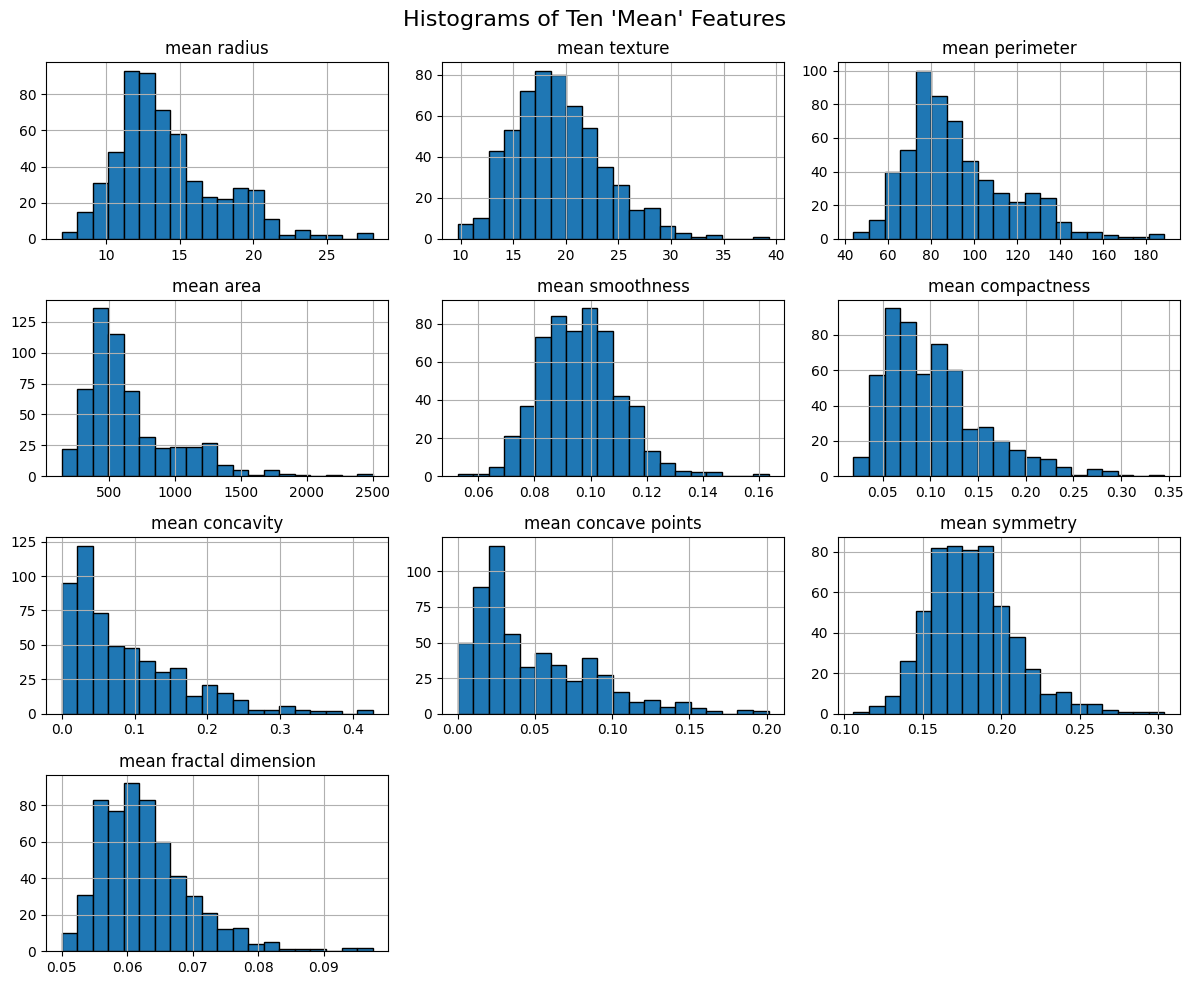

In [10]:
# TODO: histograms of the ten "mean" features (hint: df.filter(like="mean").hist)
df.filter(like="mean").hist(figsize=(12, 10), bins=20, edgecolor="black")
plt.suptitle("Histograms of Ten 'Mean' Features", fontsize=16)
plt.tight_layout()
plt.show()

**Exercise B.7 (bivariate).** Draw box plots of four features split by class. Which separate the classes best?

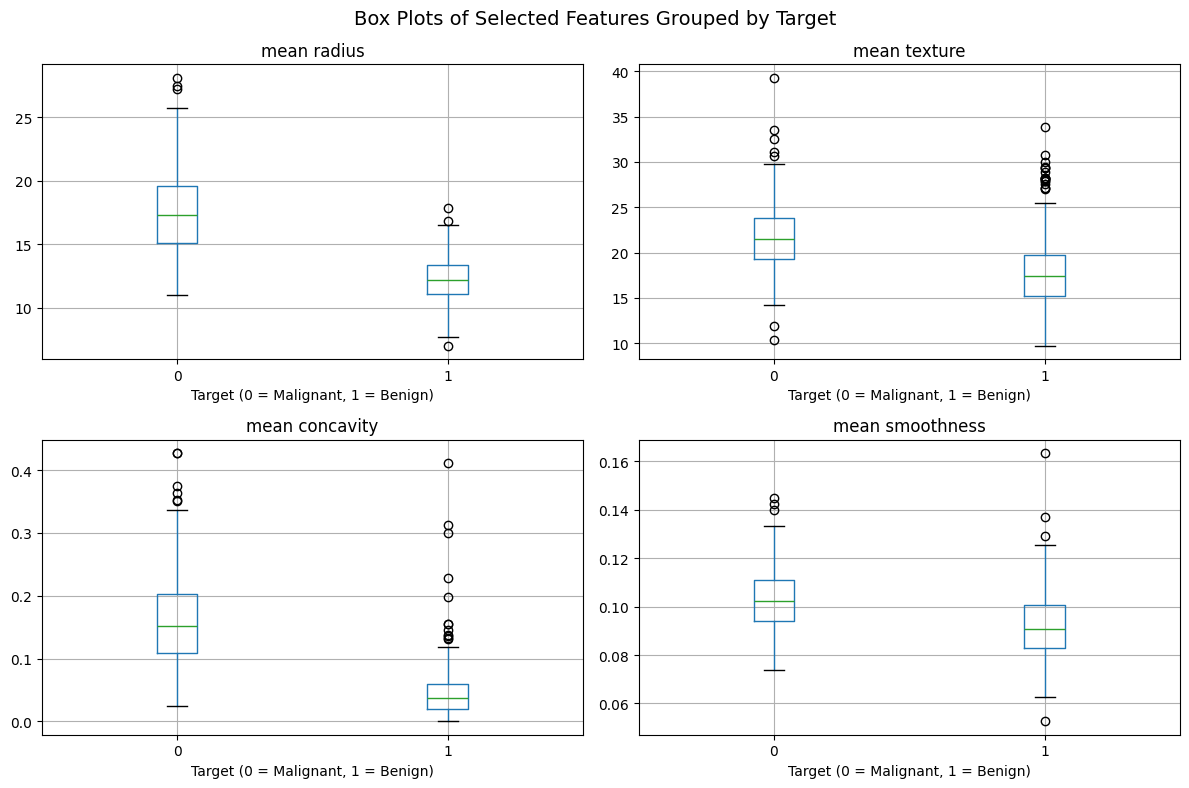

In [11]:
features = ["mean radius", "mean texture", "mean concavity", "mean smoothness"]

# TODO: one box plot per feature, grouped by target
fig, axes = plt.subplots(2, 2, figsize=(12, 8))
axes = axes.flatten()

for i, col in enumerate(features):
    df.boxplot(column=col, by="target", ax=axes[i])
    axes[i].set_title(col)
    axes[i].set_xlabel("Target (0 = Malignant, 1 = Benign)")

plt.suptitle("Box Plots of Selected Features Grouped by Target", fontsize=14)
plt.tight_layout()
plt.show()

**Exercise B.8 (multivariate).** Show a correlation heatmap of the ten `mean` features.

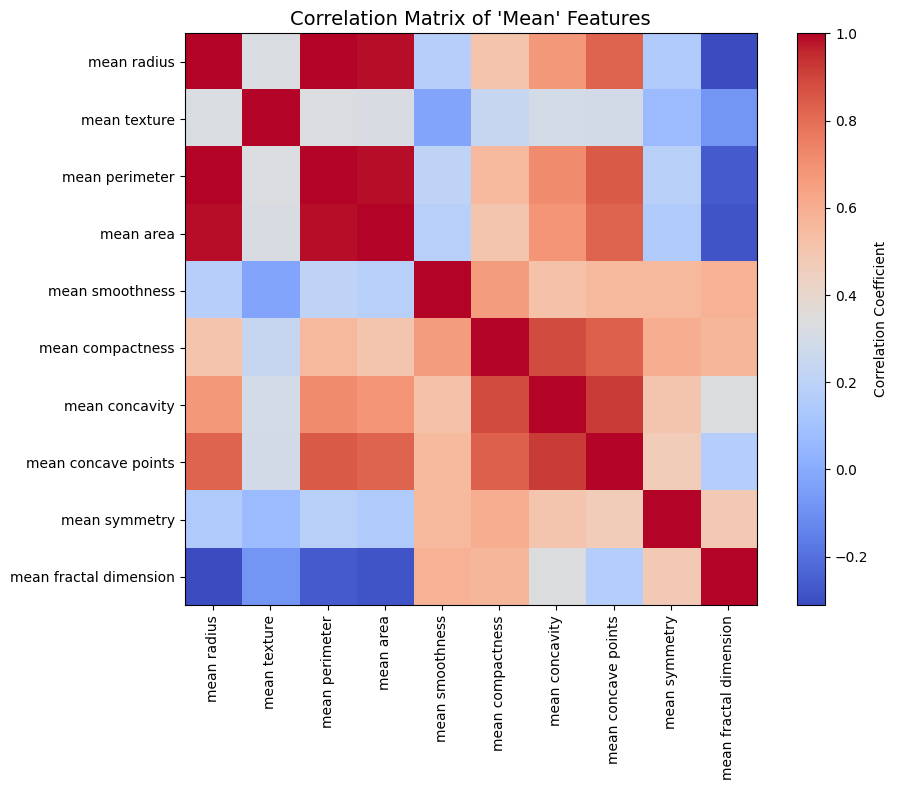

In [32]:
# TODO: correlation matrix of the "mean" features drawn with imshow
mean_df = df.filter(like="mean")
corr = mean_df.corr()

plt.figure(figsize=(10, 8))
plt.imshow(corr, cmap="coolwarm", interpolation="none")
plt.colorbar(label="Correlation Coefficient")

tick_marks = np.arange(len(mean_df.columns))
plt.xticks(tick_marks, mean_df.columns, rotation=90)
plt.yticks(tick_marks, mean_df.columns)

plt.title("Correlation Matrix of 'Mean' Features", fontsize=14)
plt.tight_layout()
plt.show()

**Exercise B.9.** Scatter `mean radius` against `mean concavity`, coloured by class.

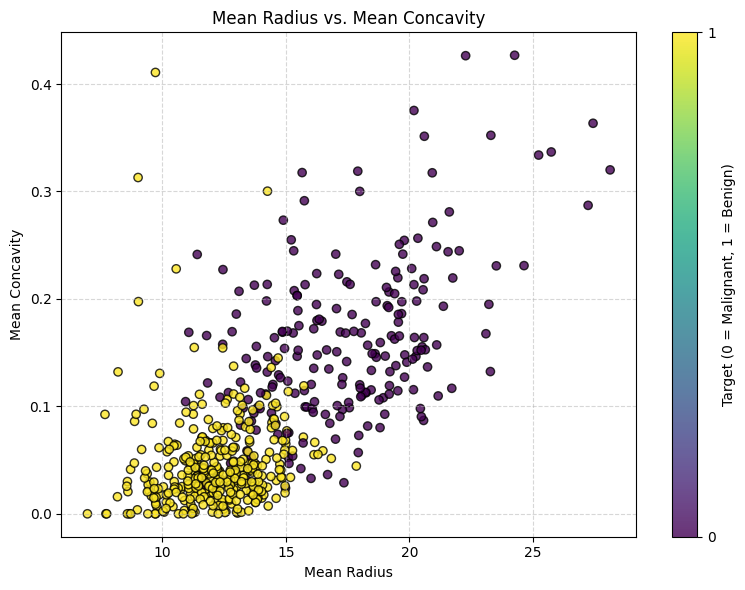

In [13]:
# TODO: coloured scatter plot with axis labels and a colourbar
plt.figure(figsize=(8, 6))
scatter = plt.scatter(
    df["mean radius"],
    df["mean concavity"],
    c=df["target"],
    cmap="viridis",
    alpha=0.8,
    edgecolors="k"
)

plt.xlabel("Mean Radius")
plt.ylabel("Mean Concavity")
plt.title("Mean Radius vs. Mean Concavity")

cbar = plt.colorbar(scatter, ticks=[0, 1])
cbar.set_label("Target (0 = Malignant, 1 = Benign)")

plt.grid(True, linestyle="--", alpha=0.5)
plt.tight_layout()
plt.show()

✏️ **Question B.10.** Which features appear redundant, and which separate the classes most clearly?

> **Your answer:**

>**Redundant features:** Size measurements like mean radius, mean perimeter, and mean area are redundant because they are strongly correlated ($r > 0.98$) and describe the same size dimension.

>**Best class separators:** Shape and boundary features like worst concave points, worst perimeter, mean concave points, and mean concavity separate malignant and benign cases most clearly.

---
## C. Prepare Data

### C.1 Data Cleaning
**Exercise C.1.** Count missing values and duplicate rows.

In [14]:
# TODO: total missing values and duplicated rows
print("Total missing values:", df.isnull().sum().sum())
print("Total duplicate rows:", df.duplicated().sum())

X = df.drop(columns="target")
y = df["target"]

Total missing values: 0
Total duplicate rows: 0


**Exercise C.2.** Count outliers per feature using the IQR rule (below Q1 − 1.5·IQR or above Q3 + 1.5·IQR) and show the 10 features with the most.

In [31]:
# TODO: IQR outlier count per feature
Q1 = X.quantile(0.25)
Q3 = X.quantile(0.75)
IQR = Q3 - Q1

outliers = ((X < (Q1 - 1.5 * IQR)) | (X > (Q3 + 1.5 * IQR))).sum()

print("10 Features with the Most Outliers:")
print(outliers.sort_values(ascending=False).head(10))

10 Features with the Most Outliers:
area error                 65
radius error               38
perimeter error            38
worst area                 35
smoothness error           30
fractal dimension error    28
compactness error          28
symmetry error             27
mean area                  25
worst fractal dimension    24
dtype: int64


✏️ **Question C.3.** Would you delete the outlying rows? Justify your decision.

> **Your answer:** I would not delete the outlying rows because in medical datasets, extreme measurement values represent real, naturally occurring severe cases of malignant tumors rather than data errors. Removing these rows would eliminate critical patterns the model needs to detect dangerous cancer cases in practice.

### C.2 Feature Selection
**Exercise C.4 (filter).** Find features whose absolute correlation with an *earlier* feature exceeds 0.95.

In [17]:
# TODO: upper-triangle of the absolute correlation matrix, then columns above 0.95
corr_matrix = X.corr().abs()
upper_tri = corr_matrix.where(np.triu(np.ones(corr_matrix.shape), k=1).astype(bool))

to_drop = [column for column in upper_tri.columns if any(upper_tri[column] > 0.95)]
print("Features with correlation > 0.95 to drop:", to_drop)

Features with correlation > 0.95 to drop: ['mean perimeter', 'mean area', 'perimeter error', 'area error', 'worst radius', 'worst perimeter', 'worst area']


**Exercise C.5 (univariate).** Rank features with `SelectKBest(f_classif)`.

In [18]:
# TODO: fit SelectKBest(f_classif, k=10) and build a sorted Series of scores
selector = SelectKBest(score_func=f_classif, k=10)
selector.fit(X, y)

kbest_scores = pd.Series(selector.scores_, index=X.columns).sort_values(ascending=False)
kbest_features = kbest_scores.head(10).index.tolist()

print("Top 10 Features selected by SelectKBest:")
print(kbest_scores.head(10))

Top 10 Features selected by SelectKBest:
worst concave points    964.385393
worst perimeter         897.944219
mean concave points     861.676020
worst radius            860.781707
mean perimeter          697.235272
worst area              661.600206
mean radius             646.981021
mean area               573.060747
mean concavity          533.793126
worst concavity         436.691939
dtype: float64


**Exercise C.6 (wrapper).** Use Recursive Feature Elimination with logistic regression on standardized data to keep 10 features.

In [19]:
# TODO: RFE(LogisticRegression, n_features_to_select=10) on standardised X; store names in rfe_features
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

model = LogisticRegression(max_iter=1000)
rfe = RFE(estimator=model, n_features_to_select=10)
rfe.fit(X_scaled, y)

rfe_features = X.columns[rfe.support_].tolist()

print("10 Features selected by RFE:")
print(rfe_features)

10 Features selected by RFE:
['mean concave points', 'radius error', 'area error', 'compactness error', 'worst radius', 'worst texture', 'worst perimeter', 'worst area', 'worst concavity', 'worst concave points']


**Exercise C.7 (embedded).** Rank features by `ExtraTreesClassifier` importance and plot the top 10.

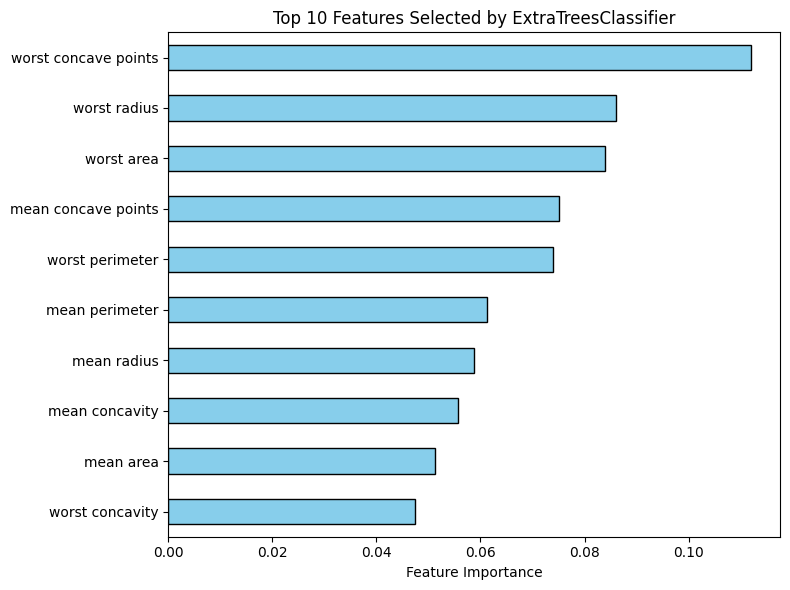

Top 10 Features selected by ExtraTrees: ['worst concave points', 'worst radius', 'worst area', 'mean concave points', 'worst perimeter', 'mean perimeter', 'mean radius', 'mean concavity', 'mean area', 'worst concavity']


In [30]:
# TODO: fit ExtraTrees (200 trees, random_state=7), store importances in imp, plot barh of top 10
et_model = ExtraTreesClassifier(n_estimators=200, random_state=7)
et_model.fit(X, y)

imp = pd.Series(et_model.feature_importances_, index=X.columns).sort_values()

top10_imp = imp.tail(10)

plt.figure(figsize=(8, 6))
top10_imp.plot(kind="barh", color="skyblue", edgecolor="black")
plt.xlabel("Feature Importance")
plt.title("Top 10 Features Selected by ExtraTreesClassifier")
plt.tight_layout()
plt.show()

et_features = top10_imp.sort_values(ascending=False).index.tolist()
print("Top 10 Features selected by ExtraTrees:", et_features)

**Exercise C.8 (decision).** Keep a feature if **at least two of the three** methods (SelectKBest top 10, RFE, ExtraTrees top 10) chose it. Store the result in a list called `selected`.

In [29]:
# TODO: vote across the three methods
from collections import Counter

all_votes = kbest_features + rfe_features + et_features

feature_counts = Counter(all_votes)

selected = [feature for feature, count in feature_counts.items() if count >= 2]

print(f"Number of selected features: {len(selected)}")
print("Selected features:", selected)

Number of selected features: 10
Selected features: ['worst concave points', 'worst perimeter', 'mean concave points', 'worst radius', 'mean perimeter', 'worst area', 'mean radius', 'mean area', 'mean concavity', 'worst concavity']


> **Caution (data leakage).** Here selection used the whole dataset to keep the exercise simple. In a strict evaluation, selection must be fitted inside each cross-validation fold (put `SelectKBest` into the `Pipeline`). You will discuss this in the final questions.

### C.3 Data Transform
**Exercise C.9.** Create a stratified 80/20 train/test split (`random_state=7`). The test set stays untouched until the very end.

In [22]:
# TODO: train_test_split with stratify=y
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=7, stratify=y
)

print(X_train.shape, X_test.shape)

(455, 30) (114, 30)


**Exercise C.10.** Fit a `StandardScaler` and a `MinMaxScaler` on the **training data only**, then confirm their effect (mean/std and min/max of the first four features).

In [25]:
# TODO: fit both scalers on X_train and print the verifying statistics

std_scaler = StandardScaler()
X_train_std = std_scaler.fit_transform(X_train)

minmax_scaler = MinMaxScaler()
X_train_minmax = minmax_scaler.fit_transform(X_train)

first_4_cols = X_train.columns[:4]

df_std = pd.DataFrame(X_train_std[:, :4], columns=first_4_cols)
df_minmax = pd.DataFrame(X_train_minmax[:, :4], columns=first_4_cols)

print("StandardScaler — Mean (target: ~0):")
print(df_std.mean().round(4))
print("\nStandardScaler — Std Dev (target: ~1):")
print(df_std.std().round(4))

print("\n" + "="*40 + "\n")

print("MinMaxScaler — Min (target: 0.0):")
print(df_minmax.min().round(4))
print("\nMinMaxScaler — Max (target: 1.0):")
print(df_minmax.max().round(4))

StandardScaler — Mean (target: ~0):
mean radius       0.0
mean texture     -0.0
mean perimeter   -0.0
mean area        -0.0
dtype: float64

StandardScaler — Std Dev (target: ~1):
mean radius       1.0011
mean texture      1.0011
mean perimeter    1.0011
mean area         1.0011
dtype: float64


MinMaxScaler — Min (target: 0.0):
mean radius       0.0
mean texture      0.0
mean perimeter    0.0
mean area         0.0
dtype: float64

MinMaxScaler — Max (target: 1.0):
mean radius       1.0
mean texture      1.0
mean perimeter    1.0
mean area         1.0
dtype: float64


**Bonus C.11.** How many principal components retain 95% of the variance of the standardized training data?

In [24]:
# TODO: fit PCA on standardised training data and use the cumulative explained variance
pca = PCA()
pca.fit(X_train_std)

cum_var = np.cumsum(pca.explained_variance_ratio_)

n_components_95 = np.argmax(cum_var >= 0.95) + 1

print(f"Number of components retaining >= 95% variance: {n_components_95}")

Number of components retaining >= 95% variance: 10


---
## D. Evaluate Algorithm

We use **stratified 10-fold cross-validation** on the training set as our test harness. Scaling is placed inside a `Pipeline` so it is re-fitted in every fold: this avoids leakage.

**Exercise D.1.** Define the six candidate models: Logistic Regression, LDA, KNN, CART, Gaussian Naive Bayes and SVM.

In [26]:
seed = 7
kfold = StratifiedKFold(n_splits=10, shuffle=True, random_state=seed)

# TODO: dictionary named models with keys LR, LDA, KNN, CART, NB, SVM
models = {
    "LR": LogisticRegression(max_iter=1000),
    "LDA": LinearDiscriminantAnalysis(),
    "KNN": KNeighborsClassifier(),
    "CART": DecisionTreeClassifier(random_state=seed),
    "NB": GaussianNB(),
    "SVM": SVC()
}

def spot_check(models, X_tr, scale):
    """Cross-validated accuracy for every model (optionally scaled inside the pipeline)."""
    results = {}
    for name, model in models.items():
        steps = ([("scale", StandardScaler())] if scale else []) + [("model", model)]
        results[name] = cross_val_score(Pipeline(steps), X_tr, y_train, cv=kfold, scoring="accuracy")
    return results

**Exercise D.2.** Run the spot-check on all features, once **raw** and once **scaled**, and tabulate the mean accuracies.

In [27]:
# TODO: call spot_check twice and build a DataFrame called summary with columns raw / scaled
raw_results = spot_check(models, X_train, scale=False)
scaled_results = spot_check(models, X_train, scale=True)

summary = pd.DataFrame({
    "raw": {name: res.mean() for name, res in raw_results.items()},
    "scaled": {name: res.mean() for name, res in scaled_results.items()}
})

print("Mean Cross-Validation Accuracy (Raw vs Scaled):")
print(summary)

Mean Cross-Validation Accuracy (Raw vs Scaled):
           raw    scaled
LR    0.944976  0.982319
LDA   0.947246  0.947246
KNN   0.922947  0.964928
CART  0.927633  0.927633
NB    0.934058  0.932029
SVM   0.898696  0.975797


✏️ **Question D.3.** Which models benefit from scaling, and why?

> **Your answer:** Distance- and gradient-based models (KNN, SVM, and Logistic Regression) benefit significantly from feature scaling. KNN and SVM depend on distance calculations and margin optimization, which can be easily dominated by features with large numerical magnitudes (such as mean area). Logistic Regression relies on gradient descent, which converges much faster and finds optimal weights when features are on a uniform scale. In contrast, tree-based models like CART and probabilistic models like Naive Bayes are scale-invariant and show little to no change after scaling.

**Exercise D.4.** Repeat with the `selected` features only (scaled). Does feature selection help?

In [28]:
# TODO: spot_check on X_train[selected] and compare against the all-features scaled results
selected_results = spot_check(models, X_train[selected], scale=True)

summary["selected_scaled"] = {name: res.mean() for name, res in selected_results.items()}
print("Comparison including Selected Features:")
print(summary)

Comparison including Selected Features:
           raw    scaled  selected_scaled
LR    0.944976  0.982319         0.960435
LDA   0.947246  0.947246         0.942995
KNN   0.922947  0.964928         0.942802
CART  0.927633  0.927633         0.925266
NB    0.934058  0.932029         0.951691
SVM   0.898696  0.975797         0.953865


**Exercise D.5.** Compare the distributions of the scaled models with a box plot.

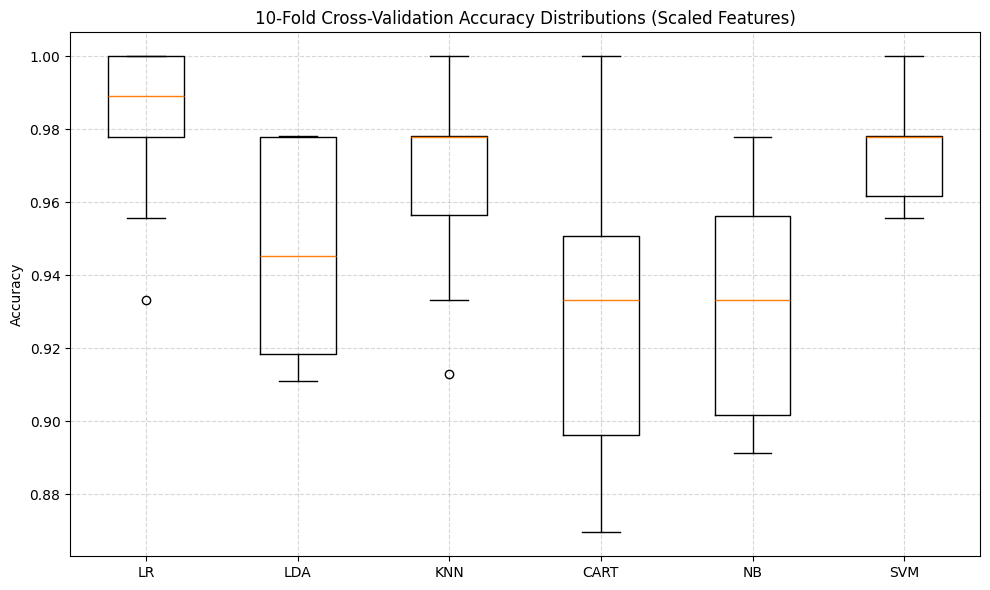

In [33]:
# TODO: box plot of the 10 fold scores per model
plt.figure(figsize=(10, 6))
plt.boxplot(scaled_results.values(), labels=scaled_results.keys())
plt.title("10-Fold Cross-Validation Accuracy Distributions (Scaled Features)")
plt.ylabel("Accuracy")
plt.grid(True, linestyle="--", alpha=0.5)
plt.tight_layout()
plt.show()

**Exercise D.6.** In a medical setting accuracy is not enough. For the best scaled model, cross-validate **accuracy, ROC-AUC and recall for the malignant class** (`pos_label=0`).

In [34]:
# TODO: cross_validate with a scoring dict including make_scorer(recall_score, pos_label=0)
scoring = {
    "accuracy": "accuracy",
    "roc_auc": "roc_auc",
    "recall_malignant": make_scorer(recall_score, pos_label=0)
}

best_pipeline = Pipeline([("scale", StandardScaler()), ("model", LogisticRegression(max_iter=1000))])
cv_results = cross_validate(best_pipeline, X_train, y_train, cv=kfold, scoring=scoring)

print("Best Scaled Model (Logistic Regression) Metrics:")
print(f"Mean Accuracy:         {cv_results['test_accuracy'].mean():.4f}")
print(f"Mean ROC-AUC:          {cv_results['test_roc_auc'].mean():.4f}")
print(f"Mean Malignant Recall: {cv_results['test_recall_malignant'].mean():.4f}")

Best Scaled Model (Logistic Regression) Metrics:
Mean Accuracy:         0.9823
Mean ROC-AUC:          0.9922
Mean Malignant Recall: 0.9647


---
## E. Improve Accuracy

### E.1 Algorithm Tuning
**Exercise E.1.** Tune the SVM (`C`, `gamma`, `kernel`) with `GridSearchCV` inside a scaling pipeline.

In [35]:
# TODO: Tune SVM using GridSearchCV inside a scaling pipeline
pipe = Pipeline([
    ("scale", StandardScaler()),
    ("svm", SVC())
])

param_grid = {
    "svm__C": [0.1, 1, 10, 100],
    "svm__gamma": ["scale", "auto", 0.01, 0.1, 1],
    "svm__kernel": ["rbf", "linear"]
}

grid = GridSearchCV(pipe, param_grid, cv=kfold, scoring="accuracy", n_jobs=-1)
grid.fit(X_train, y_train)

print(f"Best Parameters: {grid.best_params_}")
print(f"Best CV Accuracy: {grid.best_score_:.4f}")

Best Parameters: {'svm__C': 0.1, 'svm__gamma': 'scale', 'svm__kernel': 'linear'}
Best CV Accuracy: 0.9802


**Exercise E.2.** Tune KNN (`n_neighbors`, `weights`) the same way.

In [38]:
# TODO: grid over n_neighbors=[3,5,7,9,11,15,21] and weights=["uniform","distance"]
pipe_knn = Pipeline([
    ("scale", StandardScaler()),
    ("knn", KNeighborsClassifier())
])

param_grid_knn = {
    "knn__n_neighbors": [3, 5, 7, 9, 11, 15, 21],
    "knn__weights": ["uniform", "distance"]
}

grid_knn = GridSearchCV(pipe_knn, param_grid_knn, cv=kfold, scoring="accuracy", n_jobs=-1)
grid_knn.fit(X_train, y_train)

print(f"Best Parameters for KNN: {grid_knn.best_params_}")
print(f"Best CV Accuracy for KNN: {grid_knn.best_score_:.4f}")

Best Parameters for KNN: {'knn__n_neighbors': 3, 'knn__weights': 'uniform'}
Best CV Accuracy for KNN: 0.9693


### E.2 Ensembles
**Exercise E.3.** Spot-check four ensemble methods (Random Forest, Extra Trees, Gradient Boosting, AdaBoost) and one voting ensemble of the tuned SVM, tuned KNN and Random Forest.

In [41]:
# TODO: dictionary ensembles, score with spot_check(scale=False), then a hard VotingClassifier
ensembles = {
    "RF": RandomForestClassifier(n_estimators=100, random_state=seed),
    "ET": ExtraTreesClassifier(n_estimators=100, random_state=seed),
    "GBM": GradientBoostingClassifier(random_state=seed),
    "Ada": AdaBoostClassifier(random_state=seed)
}

ensemble_results = spot_check(ensembles, X_train, scale=False)

svm_best_params = {k.replace("svm__", ""): v for k, v in grid.best_params_.items()}
knn_best_params = {k.replace("knn__", ""): v for k, v in grid_knn.best_params_.items()}

tuned_svm = Pipeline([
    ("scale", StandardScaler()),
    ("svm", SVC(**svm_best_params, probability=True, random_state=seed))
])

tuned_knn = Pipeline([
    ("scale", StandardScaler()),
    ("knn", KNeighborsClassifier(**knn_best_params))
])

rf_model = RandomForestClassifier(n_estimators=100, random_state=seed)

voting_model = VotingClassifier(
    estimators=[("svm", tuned_svm), ("knn", tuned_knn), ("rf", rf_model)],
    voting="hard"
)

voting_scores = cross_val_score(voting_model, X_train, y_train, cv=kfold, scoring="accuracy")
ensemble_results["Voting"] = voting_scores

for name, scores in ensemble_results.items():
    print(f"{name} Mean CV Accuracy: {scores.mean():.4f}")

RF Mean CV Accuracy: 0.9691
ET Mean CV Accuracy: 0.9736
GBM Mean CV Accuracy: 0.9670
Ada Mean CV Accuracy: 0.9626
Voting Mean CV Accuracy: 0.9781


**Exercise E.4.** Build a leaderboard (Series sorted by mean CV accuracy) containing both tuned models, the four ensembles and the voting ensemble.

In [42]:
# TODO: leaderboard Series
leaderboard_dict = {
    "Tuned SVM": grid.best_score_,
    "Tuned KNN": grid_knn.best_score_,
    "RF": ensemble_results["RF"].mean(),
    "ET": ensemble_results["ET"].mean(),
    "GBM": ensemble_results["GBM"].mean(),
    "Ada": ensemble_results["Ada"].mean(),
    "Voting": ensemble_results["Voting"].mean()
}

leaderboard = pd.Series(leaderboard_dict).sort_values(ascending=False)
print("--- MODEL LEADERBOARD (Mean CV Accuracy) ---")
print(leaderboard)

--- MODEL LEADERBOARD (Mean CV Accuracy) ---
Tuned SVM    0.980193
Voting       0.978068
ET           0.973575
Tuned KNN    0.969275
RF           0.969130
GBM          0.966957
Ada          0.962560
dtype: float64


### E.3 Finalize the Model
**Exercise E.5.** Fit the winner on the full training set and, for the first and only time, evaluate it on the held-out **test set**. Report accuracy, the classification report and a confusion matrix.

Test Accuracy: 0.9649

Classification Report:
               precision    recall  f1-score   support

Malignant (0)       0.95      0.95      0.95        42
   Benign (1)       0.97      0.97      0.97        72

     accuracy                           0.96       114
    macro avg       0.96      0.96      0.96       114
 weighted avg       0.96      0.96      0.96       114



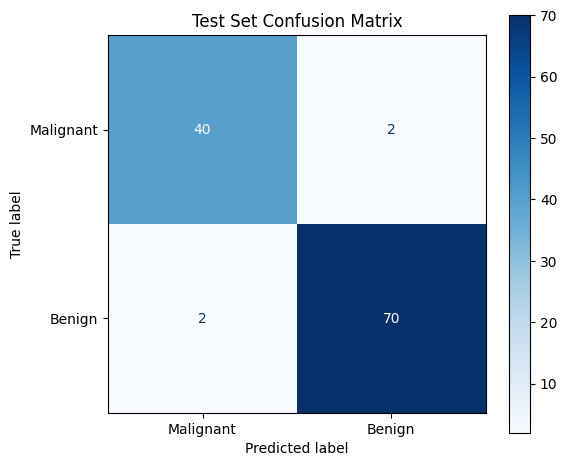

In [43]:
# TODO: pick the leaderboard winner, fit on train, predict test, print metrics, plot confusion matrix

winner_svm_params = {k.replace("svm__", ""): v for k, v in grid.best_params_.items()}
winner_model = Pipeline([
    ("scale", StandardScaler()),
    ("svm", SVC(**winner_svm_params, probability=True, random_state=seed))
])

winner_model.fit(X_train, y_train)

y_pred = winner_model.predict(X_test)

print(f"Test Accuracy: {accuracy_score(y_test, y_pred):.4f}\n")
print("Classification Report:")
print(classification_report(y_test, y_pred, target_names=["Malignant (0)", "Benign (1)"]))

fig, ax = plt.subplots(figsize=(6, 5))
ConfusionMatrixDisplay.from_predictions(
    y_test, y_pred, display_labels=["Malignant", "Benign"], cmap="Blues", ax=ax
)
plt.title("Test Set Confusion Matrix")
plt.tight_layout()
plt.show()

**Exercise E.6.** Save the model with `joblib`, reload it and confirm it reproduces predictions.

In [44]:
# TODO: joblib.dump, joblib.load, compare first 5 predictions with y_test
import joblib

joblib.dump(winner_model, "breast_cancer_model.pkl")

loaded_model = joblib.load("breast_cancer_model.pkl")

loaded_preds = loaded_model.predict(X_test[:5])
original_preds = winner_model.predict(X_test[:5])

comparison = pd.DataFrame({
    "True Label (y_test)": y_test[:5].values,
    "Original Model Preds": original_preds,
    "Loaded Model Preds": loaded_preds
})

print("First 5 Predictions Comparison:")
print(comparison)

assert (loaded_preds == original_preds).all(), "Loaded model predictions do not match!"
print("\nModel saved, reloaded, and predictions successfully verified!")

First 5 Predictions Comparison:
   True Label (y_test)  Original Model Preds  Loaded Model Preds
0                    0                     0                   0
1                    0                     0                   0
2                    1                     1                   1
3                    0                     0                   0
4                    1                     1                   1

Model saved, reloaded, and predictions successfully verified!


---
## Reflection Questions
✏️ Answer in a short paragraph each.

1. **Leakage.** Feature selection in Part C used the whole dataset. Explain why this can inflate CV scores and how you would fix it using a `Pipeline`.
2. **Metric choice.** Which metric would you report to a clinician, and why is accuracy alone insufficient?
3. **Model choice.** If two models differ by 0.3% in CV accuracy, how would you decide between them? (Think variance across folds, interpretability, training cost.)
4. **Generalization.** How would your conclusions change with a much smaller or much more imbalanced dataset?
5. **Extension.** Repeat the workbook with a dataset of your choice (e.g., loaded from an ARFF file) and note which steps change.

**Submission checklist:** all `TODO`s completed · all cells run top to bottom · written answers filled in · final test accuracy reported once.

**1. Leakage.** Feature selection in Part C used the whole dataset. Explain why this can inflate CV scores and how you would fix it using a Pipeline.
>Selecting features on the entire dataset exposes the feature selector to information from test folds, artificially inflating cross-validation performance. To prevent this data leakage, place the feature selector (such as SelectKBest) inside a scikit-learn Pipeline so features are refitted using only the training fold during each CV split.

**2. Metric choice.** Which metric would you report to a clinician, and why is accuracy alone insufficient?
>I would report Recall (Sensitivity) for malignant cases alongside ROC-AUC to a clinician. Accuracy alone is insufficient because a model could achieve high accuracy by guessing "benign" most of the time while completely missing dangerous cancer cases (false negatives).

**3. Model choice.** If two models differ by 0.3% in CV accuracy, how would you decide between them? (Think variance across folds, interpretability, training cost.)
>When two models differ by only 0.3% in CV accuracy, I would choose based on performance stability (lower score variance across folds), model simplicity (preferring interpretable models like Logistic Regression or SVM over complex ensembles for medical transparency), and computational efficiency.

**4. Generalization.** How would your conclusions change with a much smaller or much more imbalanced dataset?
>A smaller dataset increases overfitting risk and score variance, requiring simpler models and stronger regularization. A more imbalanced dataset renders accuracy unreliable, requiring metrics like PR-AUC and F1-score, alongside techniques like SMOTE or class weighting to detect rare positive cases.

**5. Extension.** Repeat the workbook with a dataset of your choice (e.g., loaded from an ARFF file) and note which steps change.
>